# Day 4 — Data cleaning: missing values, duplicates and inconsistent categories

Run each cell with **Shift + Enter**, from the top. The original file is never changed: every step works on a copy, and the last cell saves `student_data_clean.csv`.

## 1. Introduction to data cleaning

In [ ]:
# Get the dataset: Colab starts with an empty folder, so download the file the first time
import os
import urllib.request

URL = "https://raw.githubusercontent.com/neerajb1/learnforge-notebooks/main/ai-ml-120/day-004/data/student_data_dirty.csv"
if not os.path.exists("student_data_dirty.csv"):
    urllib.request.urlretrieve(URL, "student_data_dirty.csv")

In [ ]:
import pandas as pd

pd.set_option("display.width", 120)    # print wide tables on one line

# Load the messy student dataset. We never change `raw`: every cleaning step works on a copy.
raw = pd.read_csv("student_data_dirty.csv")
print(raw)

   Student Class     Age  StudyHours  Attendance PreviousScore  ExamScore Passed
0       S1     A      10         1.0        60.0           40%       35.0  False
1       S2     A      11         2.0        70.0           50%       45.0     no
2       S3     B     NaN         3.0        80.0            60       55.0   True
3       S4     b      12         4.0         NaN           70%       65.0    yes
4       S5    B       11         NaN        95.0            80       75.0   True
5       S6     C  eleven         3.0        85.0           55%        NaN  False
6       S7     c      12         4.0        90.0            65       70.0   True
7       S7     c      12         4.0        90.0            65       70.0   True
8       S8     C      11         2.0        75.0           45%      750.0   True
9       S9     A      12         5.0        92.0            75       80.0   TRUE
10     S10   NaN      11         1.0        65.0           35%       40.0  False


In [ ]:
# Inspect the structure
print("Shape:", raw.shape)
raw.info()          # info() prints its own report

print("\nMissing values:")
print(raw.isnull().sum())
print("\nDuplicate rows:", raw.duplicated().sum())

Shape: (11, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Student        11 non-null     object 
 1   Class          10 non-null     object 
 2   Age            10 non-null     object 
 3   StudyHours     10 non-null     float64
 4   Attendance     10 non-null     float64
 5   PreviousScore  11 non-null     object 
 6   ExamScore      10 non-null     float64
 7   Passed         11 non-null     object 
dtypes: float64(3), object(5)
memory usage: 836.0+ bytes

Missing values:
Student          0
Class            1
Age              1
StudyHours       1
Attendance       1
PreviousScore    0
ExamScore        1
Passed           0
dtype: int64

Duplicate rows: 1


In [ ]:
# Data types: Age should be a number, but pandas read it as text (object)
print(raw.dtypes)

# Convert on a copy: text that isn't a number ("eleven") becomes NaN (missing)
df = raw.copy()
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
print("\nAge after conversion:", df["Age"].dtype)
print(df["Age"].tolist())

Student           object
Class             object
Age               object
StudyHours       float64
Attendance       float64
PreviousScore     object
ExamScore        float64
Passed            object
dtype: object

Age after conversion: float64
[10.0, 11.0, nan, 12.0, 11.0, nan, 12.0, 12.0, 11.0, 12.0, 11.0]


In [ ]:
# Detect duplicates: show every copy of a repeated row
print(raw[raw.duplicated(keep=False)])
print("\nDuplicate rows:", raw.duplicated().sum())

  Student Class Age  StudyHours  Attendance PreviousScore  ExamScore Passed
6      S7     c  12         4.0        90.0            65       70.0   True
7      S7     c  12         4.0        90.0            65       70.0   True

Duplicate rows: 1


In [ ]:
# A quick summary before cleaning (numeric columns only: Age is still text in `raw`)
print(raw.describe())

       StudyHours  Attendance   ExamScore
count    10.00000   10.000000   10.000000
mean      2.90000   80.200000  128.500000
std       1.37032   12.218383  218.912083
min       1.00000   60.000000   35.000000
25%       2.00000   71.250000   47.500000
50%       3.00000   82.500000   67.500000
75%       4.00000   90.000000   73.750000
max       5.00000   95.000000  750.000000


## 2. Missing values

In [ ]:
# Count missing values in each column of the original file
print(raw.isnull().sum())
print("\nValues present:", raw.notnull().sum().sum(), "| missing:", raw.isnull().sum().sum())

Student          0
Class            1
Age              1
StudyHours       1
Attendance       1
PreviousScore    0
ExamScore        1
Passed           0
dtype: int64

Values present: 83 | missing: 5


In [ ]:
# Look at the rows with gaps before deciding anything: why is each value missing?
print(raw[raw.isnull().any(axis=1)])

   Student Class     Age  StudyHours  Attendance PreviousScore  ExamScore Passed
2       S3     B     NaN         3.0        80.0            60       55.0   True
3       S4     b      12         4.0         NaN           70%       65.0    yes
4       S5    B       11         NaN        95.0            80       75.0   True
5       S6     C  eleven         3.0        85.0           55%        NaN  False
10     S10   NaN      11         1.0        65.0           35%       40.0  False


In [ ]:
# Work on a copy without the exact duplicate, so it can't count twice
base = df.drop_duplicates().copy()

# Fill with the mean
mean_fill = base["Attendance"].fillna(base["Attendance"].mean())
print("Mean attendance:", round(base["Attendance"].mean(), 1))
print("S4 gets:", round(mean_fill[base["Student"] == "S4"].iloc[0], 1))

Mean attendance: 79.1
S4 gets: 79.1


In [ ]:
# Fill with the median: the middle value, not pulled by extreme values
median_fill = base["Attendance"].fillna(base["Attendance"].median())
print("Median attendance:", base["Attendance"].median())
print("S4 gets:", median_fill[base["Student"] == "S4"].iloc[0])

Median attendance: 80.0
S4 gets: 80.0


In [ ]:
# Fill with a fixed value: 0 would claim S4 never attended, and pulls the average down
fixed_fill = base["Attendance"].fillna(0)
print("Average with 0 filled in:", round(fixed_fill.mean(), 1))
print("Average of the known values:", round(base["Attendance"].mean(), 1))

Average with 0 filled in: 71.2
Average of the known values: 79.1


In [ ]:
# The mode (most frequent value) of Class, before the spellings are fixed
print(base["Class"].value_counts(dropna=False))
print("Mode:", base["Class"].mode()[0])

# After fixing the spellings (Section 4) it's a three-way tie: the mode is no real answer
print()
print(base["Class"].str.strip().str.title().value_counts())

Class
A      3
C      2
B      1
b      1
B      1
c      1
NaN    1
Name: count, dtype: int64
Mode: A

Class
A    3
B    3
C    3
Name: count, dtype: int64


In [ ]:
# Drop every row with any missing value
dropped = base.dropna()
print("Rows before:", len(base), "| after dropna():", len(dropped))

# Drop only the rows missing the exam score, the value a model would learn to predict
print("Rows after dropna(subset=['ExamScore']):", len(base.dropna(subset=["ExamScore"])))

Rows before: 10 | after dropna(): 5
Rows after dropna(subset=['ExamScore']): 9


In [ ]:
# Our choices for this dataset, applied to a copy
filled = base.copy()
for col in ["Age", "StudyHours", "Attendance"]:
    filled[col] = filled[col].fillna(filled[col].median())   # numbers: the median, an estimate
filled["Class"] = filled["Class"].fillna("Unknown")          # a category: a label, not a guess
filled = filled.dropna(subset=["ExamScore"])                 # the score: drop the row
print(filled.isnull().sum().sum(), "missing values left,", len(filled), "rows")
print(filled[["Student", "Class", "Age", "StudyHours", "Attendance"]])

0 missing values left, 9 rows
   Student    Class   Age  StudyHours  Attendance
0       S1        A  10.0         1.0        60.0
1       S2        A  11.0         2.0        70.0
2       S3        B  11.0         3.0        80.0
3       S4        b  12.0         4.0        80.0
4       S5       B   11.0         3.0        95.0
6       S7        c  12.0         4.0        90.0
8       S8        C  11.0         2.0        75.0
9       S9        A  12.0         5.0        92.0
10     S10  Unknown  11.0         1.0        65.0


## 3. Duplicates and data types

In [ ]:
# Exact duplicates: every column matches an earlier row
print("Exact duplicate rows:", raw.duplicated().sum())
print(raw[raw.duplicated(keep=False)])

Exact duplicate rows: 1
  Student Class Age  StudyHours  Attendance PreviousScore  ExamScore Passed
6      S7     c  12         4.0        90.0            65       70.0   True
7      S7     c  12         4.0        90.0            65       70.0   True


In [ ]:
# Business-key duplicates: the same Student ID more than once, even if other values differ
print("Repeated Student IDs:", raw.duplicated(subset=["Student"]).sum())

# Sharing a value is not a duplicate: many students are in the same class
print("Rows sharing a Class with an earlier row:", raw["Class"].duplicated().sum())

Repeated Student IDs: 1
Rows sharing a Class with an earlier row: 4


In [ ]:
# Remove exact duplicates on a copy; the original keeps all its rows
deduped = raw.drop_duplicates()
print("Original rows:", len(raw), "| after drop_duplicates():", len(deduped))

Original rows: 11 | after drop_duplicates(): 10


In [ ]:
# The data type pandas chose for each column
print(raw.dtypes)

Student           object
Class             object
Age               object
StudyHours       float64
Attendance       float64
PreviousScore     object
ExamScore        float64
Passed            object
dtype: object


In [ ]:
# astype() converts only when every value can be converted
try:
    raw["Age"].astype(float)
except ValueError as error:
    print("astype(float) fails:", error)

# pd.to_numeric(errors="coerce") turns what it can't read into NaN, a missing value to handle
print(raw["Age"].tolist())
print(pd.to_numeric(raw["Age"], errors="coerce").tolist())

astype(float) fails: could not convert string to float: 'eleven'
['10', '11', nan, '12', '11', 'eleven', '12', '12', '11', '12', '11']
[10.0, 11.0, nan, 12.0, 11.0, nan, 12.0, 12.0, 11.0, 12.0, 11.0]


In [ ]:
# Mixed formats: PreviousScore is text, and some values have a % sign
print(raw["PreviousScore"].tolist())
previous = pd.to_numeric(raw["PreviousScore"].astype(str).str.replace("%", ""), errors="coerce")
print(previous.tolist())
print(previous.dtype)

['40%', '50%', '60', '70%', '80', '55%', '65', '65', '45%', '75', '35%']
[40, 50, 60, 70, 80, 55, 65, 65, 45, 75, 35]
int64


In [ ]:
# Apply the conversion to our working copy, then check the schema
filled["PreviousScore"] = pd.to_numeric(filled["PreviousScore"].astype(str).str.replace("%", ""), errors="coerce")
print(filled.dtypes)
print("\nMissing values:", filled.isnull().sum().sum())

Student           object
Class             object
Age              float64
StudyHours       float64
Attendance       float64
PreviousScore      int64
ExamScore        float64
Passed            object
dtype: object

Missing values: 0


## 4. Inconsistent categories

In [ ]:
# Every spelling of Class in the original file
print(raw["Class"].unique())
print(raw["Class"].value_counts(dropna=False))

['A' 'B' 'b' 'B ' 'C' 'c' nan]
Class
A      3
c      2
C      2
b      1
B      1
B      1
NaN    1
Name: count, dtype: int64


In [ ]:
# 1. Standardise the format: remove spaces and use lower case
cls = filled["Class"].astype("string").str.strip().str.lower()
print(cls.unique().tolist())

# 2. Map each known spelling to one standard name, written out explicitly
class_map = {"a": "A", "b": "B", "c": "C", "unknown": "Unknown"}

# 3. Review any value the map doesn't cover before replacing anything
print("Values to review:", sorted(set(cls.dropna()) - set(class_map)))

filled["Class"] = cls.map(class_map)
print(filled["Class"].value_counts())

['a', 'b', 'c', 'unknown']
Values to review: []
Class
A          3
B          3
C          2
Unknown    1
Name: count, dtype: int64


In [ ]:
# Another category column: Passed mixes True/False with TRUE and yes/no
print(raw["Passed"].unique().tolist())
print(raw["Passed"].value_counts())

['False', 'no', 'True', 'yes', 'TRUE']
Passed
True     5
False    3
no       1
yes      1
TRUE     1
Name: count, dtype: int64


In [ ]:
# A reusable cleaning function: known spellings become True/False, anything else becomes missing for review
def clean_passed(value):
    if pd.isna(value):
        return pd.NA
    v = str(value).strip().lower()
    if v in ["true", "yes"]:
        return True
    if v in ["false", "no"]:
        return False
    return pd.NA

filled["Passed"] = filled["Passed"].apply(clean_passed).astype("boolean")
print(filled["Passed"].tolist())

[False, False, True, True, True, True, True, True, False]


In [ ]:
# Verify the cleaned categories
print("Cleaned Class values:", sorted(filled["Class"].unique()))
print("Cleaned Passed values:", sorted(filled["Passed"].unique().tolist()))
print("Missing after cleaning:", filled[["Class", "Passed"]].isnull().sum().sum())

Cleaned Class values: ['A', 'B', 'C', 'Unknown']
Cleaned Passed values: [False, True]
Missing after cleaning: 0


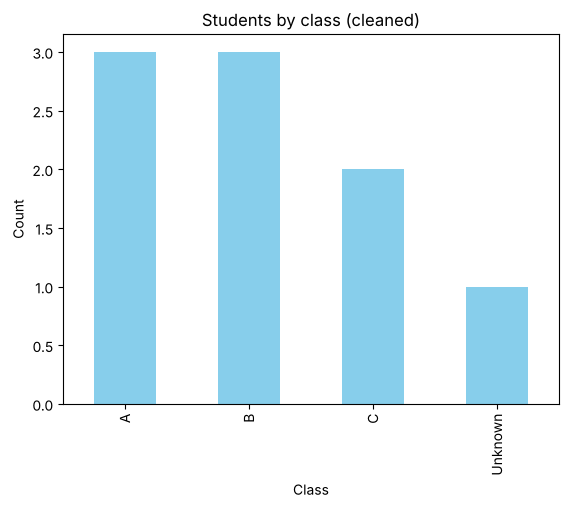

In [ ]:
import matplotlib.pyplot as plt

# A bar chart of the cleaned classes
filled["Class"].value_counts().sort_index().plot(kind="bar", color="skyblue")
plt.title("Students by class (cleaned)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

## 5. Outliers and data quality checks

In [ ]:
# Understanding outliers: sort by exam score and look at both ends
print(filled["ExamScore"].describe())
print()
print(filled.sort_values("ExamScore")[["Student", "Class", "StudyHours", "Attendance", "PreviousScore", "ExamScore"]])

count      9.000000
mean     135.000000
std      231.165525
min       35.000000
25%       45.000000
50%       65.000000
75%       75.000000
max      750.000000
Name: ExamScore, dtype: float64

   Student    Class  StudyHours  Attendance  PreviousScore  ExamScore
0       S1        A         1.0        60.0             40       35.0
10     S10  Unknown         1.0        65.0             35       40.0
1       S2        A         2.0        70.0             50       45.0
2       S3        B         3.0        80.0             60       55.0
3       S4        B         4.0        80.0             70       65.0
6       S7        C         4.0        90.0             65       70.0
4       S5        B         3.0        95.0             80       75.0
9       S9        A         5.0        92.0             75       80.0
8       S8        C         2.0        75.0             45      750.0


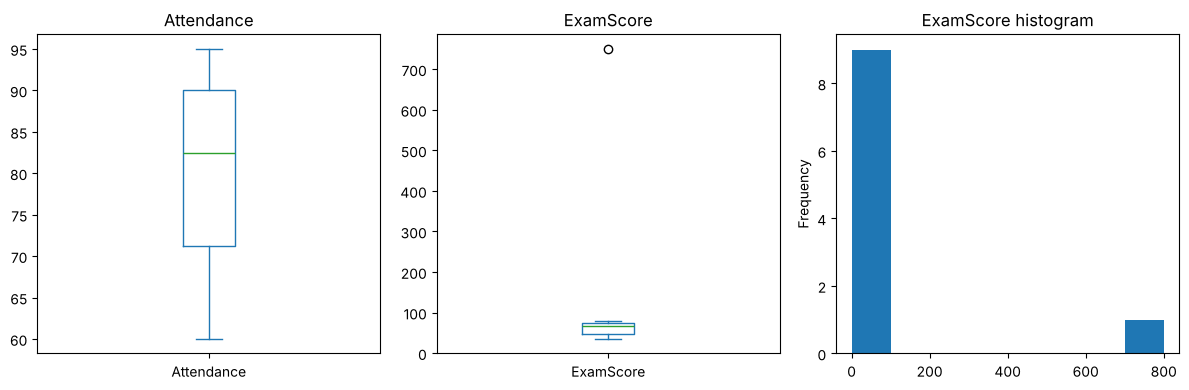

In [ ]:
import matplotlib.pyplot as plt

# Visualize outliers in the original file: box plots and a histogram (pandas skips the missing values)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
raw["Attendance"].plot(kind="box", ax=axes[0], title="Attendance")
raw["ExamScore"].plot(kind="box", ax=axes[1], title="ExamScore")
raw["ExamScore"].plot(kind="hist", bins=range(0, 801, 100), ax=axes[2], title="ExamScore histogram")
plt.tight_layout()
plt.show()

In [ ]:
# Detecting outliers with the IQR rule
Q1 = filled["ExamScore"].quantile(0.25)
Q3 = filled["ExamScore"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print(f"Q1: {Q1}  Q3: {Q3}  IQR: {IQR}")
print(f"Lower bound: {lower}  Upper bound: {upper}")

outliers = filled[(filled["ExamScore"] < lower) | (filled["ExamScore"] > upper)]
print(outliers[["Student", "ExamScore"]])

Q1: 45.0  Q3: 75.0  IQR: 30.0
Lower bound: 0.0  Upper bound: 120.0
  Student  ExamScore
8      S8      750.0


In [ ]:
# The same rule for every numeric column
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

for col in ["Age", "StudyHours", "Attendance", "PreviousScore", "ExamScore"]:
    low, high = iqr_bounds(filled[col])
    flagged = filled.loc[~filled[col].between(low, high), "Student"].tolist()
    print(f"{col:<14} {low:>6} to {high:<6} flagged: {flagged}")

Age               9.5 to 13.5   flagged: []
StudyHours       -1.0 to 7.0    flagged: []
Attendance       40.0 to 120.0  flagged: []
PreviousScore     7.5 to 107.5  flagged: []
ExamScore         0.0 to 120.0  flagged: ['S8']


In [ ]:
# Valid ranges: which values are impossible, not just unusual?
rules = {"Age": (5, 18), "StudyHours": (0, 24), "Attendance": (0, 100), "PreviousScore": (0, 100), "ExamScore": (0, 100)}
for col, (low, high) in rules.items():
    bad = filled.loc[~filled[col].between(low, high), "Student"].tolist()
    print(f"{col:<14} must be {low}-{high}: {bad}")

Age            must be 5-18: []
StudyHours     must be 0-24: []
Attendance     must be 0-100: []
PreviousScore  must be 0-100: []
ExamScore      must be 0-100: ['S8']


In [ ]:
# Investigate: read the whole record before deciding
print(filled[filled["Student"] == "S8"].to_string(index=False))
print("\nStudents with similar study hours:")
print(filled[filled["StudyHours"] == 2][["Student", "Attendance", "PreviousScore", "ExamScore"]].to_string(index=False))

Student Class  Age  StudyHours  Attendance  PreviousScore  ExamScore  Passed
     S8     C 11.0         2.0        75.0             45      750.0    True

Students with similar study hours:
Student  Attendance  PreviousScore  ExamScore
     S2        70.0             50       45.0
     S8        75.0             45      750.0


In [ ]:
# Cap (clip): values outside 0-100 become the nearest limit
capped = filled["ExamScore"].clip(0, 100)
print("S8 after capping:", capped[filled["Student"] == "S8"].iloc[0])
print("Mean before:", round(filled["ExamScore"].mean(), 1), "| after capping:", round(capped.mean(), 1))

S8 after capping: 100.0
Mean before: 135.0 | after capping: 62.8


In [ ]:
# Remove: keep only the rows with a valid score
removed = filled[filled["ExamScore"].between(0, 100)]
print("Rows before:", len(filled), "| after removing:", len(removed))
print("Mean after removing:", round(removed["ExamScore"].mean(), 1))

Rows before: 9 | after removing: 8
Mean after removing: 58.1


In [ ]:
# Our decision: 750 is impossible and we can't find the real score, so remove S8's row
before = len(filled)
filled = filled[filled["ExamScore"].between(0, 100)].copy()
print("Rows:", before, "->", len(filled))

Rows: 9 -> 8


In [ ]:
# Final data quality checks
print("Missing values:", filled.isnull().sum().sum())
print("Duplicate rows:", filled.duplicated().sum())
print("Repeated Student IDs:", filled["Student"].duplicated().sum())
print("Values outside their valid range:", sum((~filled[c].between(lo, hi)).sum() for c, (lo, hi) in rules.items()))
print("Classes:", sorted(filled["Class"].unique()))
print(filled.dtypes)

Missing values: 0
Duplicate rows: 0
Repeated Student IDs: 0
Values outside their valid range: 0
Classes: ['A', 'B', 'C', 'Unknown']
Student           object
Class             object
Age              float64
StudyHours       float64
Attendance       float64
PreviousScore      int64
ExamScore        float64
Passed           boolean
dtype: object


In [ ]:
# Compare before and after: ExamScore in the original file and in the cleaned data
print("Rows:", len(raw), "->", len(filled))
print(pd.DataFrame({"Before": raw["ExamScore"].describe(), "After": filled["ExamScore"].describe()}).round(1))

Rows: 11 -> 8
       Before  After
count    10.0    8.0
mean    128.5   58.1
std     218.9   16.9
min      35.0   35.0
25%      47.5   43.8
50%      67.5   60.0
75%      73.8   71.2
max     750.0   80.0


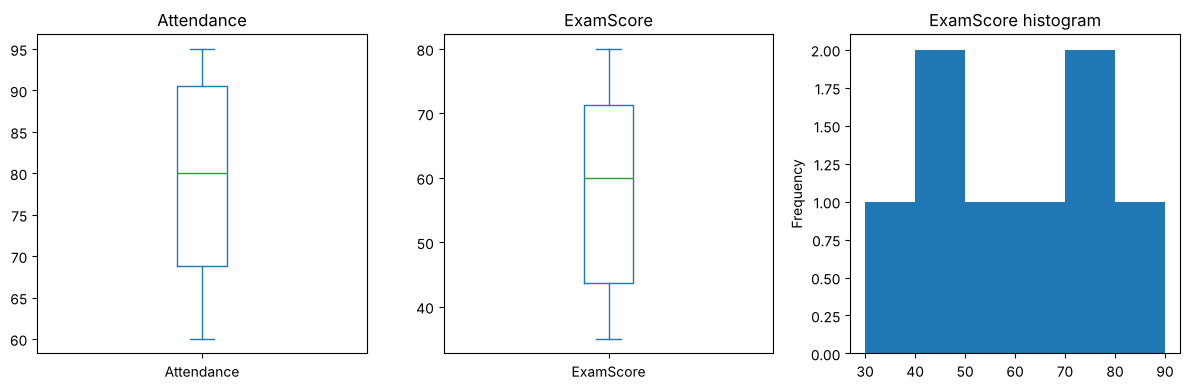

In [ ]:
# The same charts after cleaning
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
filled["Attendance"].plot(kind="box", ax=axes[0], title="Attendance")
filled["ExamScore"].plot(kind="box", ax=axes[1], title="ExamScore")
filled["ExamScore"].plot(kind="hist", bins=range(30, 91, 10), ax=axes[2], title="ExamScore histogram")
plt.tight_layout()
plt.show()

## 6. Practice and mini project: clean the dataset from start to finish

In [ ]:
# Mini project: start again from the original file
project = pd.read_csv("student_data_dirty.csv")
print("Shape:", project.shape)
print(project.head())

Shape: (11, 8)
  Student Class  Age  StudyHours  Attendance PreviousScore  ExamScore Passed
0      S1     A   10         1.0        60.0           40%       35.0  False
1      S2     A   11         2.0        70.0           50%       45.0     no
2      S3     B  NaN         3.0        80.0            60       55.0   True
3      S4     b   12         4.0         NaN           70%       65.0    yes
4      S5    B    11         NaN        95.0            80       75.0   True


In [ ]:
# The whole cleaning pipeline in one function: every line applies a decision made in Sections 2-5
def clean_students(raw):
    df = raw.drop_duplicates().copy()                       # Section 3: S7's exact copy
    df["Age"] = pd.to_numeric(df["Age"], errors="coerce")   # Section 3: "eleven" becomes missing
    df["PreviousScore"] = pd.to_numeric(df["PreviousScore"].astype(str).str.replace("%", ""), errors="coerce")
    class_map = {"a": "A", "b": "B", "c": "C", "unknown": "Unknown"}   # Section 4: explicit mapping
    df["Class"] = df["Class"].fillna("Unknown").astype("string").str.strip().str.lower().map(class_map)
    df["Passed"] = df["Passed"].apply(clean_passed).astype("boolean")
    for col in ["Age", "StudyHours", "Attendance"]:         # Section 2: medians for these gaps only
        df[col] = df[col].fillna(df[col].median())
    df = df.dropna(subset=["ExamScore"])                    # Section 2: no score to learn from
    df = df[df["ExamScore"].between(0, 100)]                # Section 5: S8's impossible 750, investigated
    return df.reset_index(drop=True)

clean = clean_students(project)
print(clean)
print("\nOriginal rows:", len(project), "| clean rows:", len(clean))
print("Same as the step-by-step result:", clean.equals(filled.reset_index(drop=True)))
print("The original file is unchanged:", project.equals(pd.read_csv("student_data_dirty.csv")))

  Student    Class   Age  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1        A  10.0         1.0        60.0             40       35.0   False
1      S2        A  11.0         2.0        70.0             50       45.0   False
2      S3        B  11.0         3.0        80.0             60       55.0    True
3      S4        B  12.0         4.0        80.0             70       65.0    True
4      S5        B  11.0         3.0        95.0             80       75.0    True
5      S7        C  12.0         4.0        90.0             65       70.0    True
6      S9        A  12.0         5.0        92.0             75       80.0    True
7     S10  Unknown  11.0         1.0        65.0             35       40.0   False

Original rows: 11 | clean rows: 8
Same as the step-by-step result: True
The original file is unchanged: True


In [ ]:
# Compare missing values before and after cleaning
print(pd.DataFrame({"Before": project.isnull().sum(), "After": clean.isnull().sum()}))

               Before  After
Student             0      0
Class               1      0
Age                 1      0
StudyHours          1      0
Attendance          1      0
PreviousScore       0      0
ExamScore           1      0
Passed              0      0


In [ ]:
# Compare duplicates before and after cleaning
print("Rows:", len(project), "->", len(clean))
print("Duplicate rows:", project.duplicated().sum(), "->", clean.duplicated().sum())
print("Repeated Student IDs:", project["Student"].duplicated().sum(), "->", clean["Student"].duplicated().sum())

Rows: 11 -> 8
Duplicate rows: 1 -> 0
Repeated Student IDs: 1 -> 0


In [ ]:
# Compare data types before and after cleaning
print(pd.DataFrame({"Before": project.dtypes, "After": clean.dtypes}))

                Before    After
Student         object   object
Class           object   object
Age             object  float64
StudyHours     float64  float64
Attendance     float64  float64
PreviousScore   object    int64
ExamScore      float64  float64
Passed          object  boolean


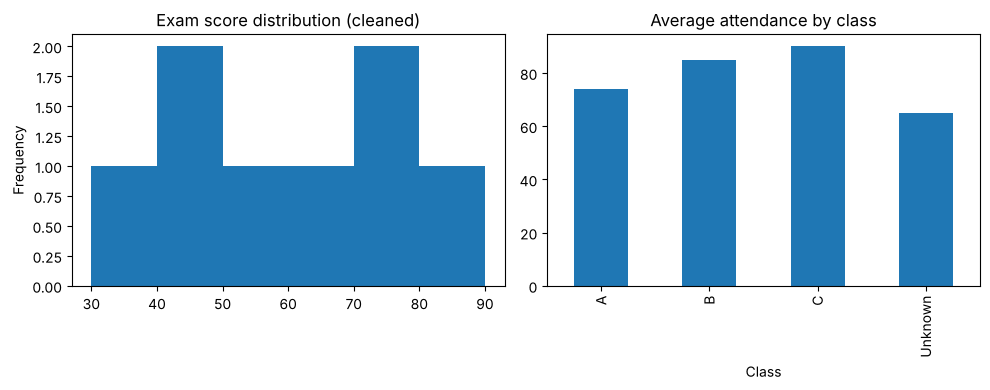

In [ ]:
# Visualize the cleaned data
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
clean["ExamScore"].plot(kind="hist", bins=range(30, 91, 10), ax=axes[0], title="Exam score distribution (cleaned)")
clean.groupby("Class")["Attendance"].mean().plot(kind="bar", ax=axes[1], title="Average attendance by class")
plt.tight_layout()
plt.show()

In [ ]:
# Analysis answers
print("1. Average exam score by class:")
print(clean.groupby("Class")["ExamScore"].mean().round(1).to_string())

print("\n2. Students with attendance below 75%:")
print(clean[clean["Attendance"] < 75][["Student", "Attendance"]].to_string(index=False))

print("\n3. The three highest exam scores:")
print(clean.nlargest(3, "ExamScore")[["Student", "ExamScore"]].to_string(index=False))

print("\n4. Mean exam score before and after:", round(project["ExamScore"].mean(), 1), "->", round(clean["ExamScore"].mean(), 1))

1. Average exam score by class:
Class
A          53.3
B          65.0
C          70.0
Unknown    40.0

2. Students with attendance below 75%:
Student  Attendance
     S1        60.0
     S2        70.0
    S10        65.0

3. The three highest exam scores:
Student  ExamScore
     S9       80.0
     S5       75.0
     S7       70.0

4. Mean exam score before and after: 128.5 -> 58.1


In [ ]:
# Save your work: write the cleaned file, then read it back to check it
clean.to_csv("student_data_clean.csv", index=False)
saved = pd.read_csv("student_data_clean.csv")
print("Saved student_data_clean.csv:", saved.shape[0], "rows,", saved.shape[1], "columns")
print("Missing values in the saved file:", saved.isnull().sum().sum())

# In Colab, download the file to your computer:
# from google.colab import files
# files.download("student_data_clean.csv")

Saved student_data_clean.csv: 8 rows, 8 columns
Missing values in the saved file: 0
